In [2]:
%pip install yfinance pandas numpy matplotlib scikit-learn torch

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: C:\Users\RAKSHITHA S N\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


## 2. Import libraries

In [3]:
import copy
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler

# Reproducibility: helps make the initial model weights repeatable.
torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


In [4]:
START_DATE = "2018-01-01"
END_DATE = "2026-01-01"       # exclusive
TICKERS = ["AAPL", "MSFT", "GOOG"]

SEQUENCE_LENGTH = 30
TRAIN_RATIO = 0.80
HIDDEN_SIZE = 32
NUM_LAYERS = 2
EPOCHS = 100
LEARNING_RATE = 0.001

print(f"Companies: {TICKERS}")
print(f"Date range: {START_DATE} to {END_DATE} (end date exclusive)")

Companies: ['AAPL', 'MSFT', 'GOOG']
Date range: 2018-01-01 to 2026-01-01 (end date exclusive)


In [5]:
def download_close_prices(ticker, start_date, end_date):
    data = yf.download(
        ticker,
        start=start_date,
        end=end_date,
        auto_adjust=False,
        progress=False
    )

    if data.empty:
        raise ValueError(f"No data returned for {ticker}. Check the ticker and date range.")

    # Recent yfinance versions can return MultiIndex columns even for one ticker.
    if isinstance(data.columns, pd.MultiIndex):
        if ("Close", ticker) in data.columns:
            close = data[("Close", ticker)]
        else:
            close_columns = [col for col in data.columns if col[0] == "Close"]
            if not close_columns:
                raise ValueError(f"Could not find Close price for {ticker}.")
            close = data[close_columns[0]]
    else:
        if "Close" not in data.columns:
            raise ValueError(f"Could not find Close price for {ticker}.")
        close = data["Close"]

    close = pd.to_numeric(close, errors="coerce").dropna()
    close = close[~close.index.duplicated(keep="first")].sort_index()

    if len(close) <= SEQUENCE_LENGTH + 10:
        raise ValueError(f"Not enough observations for {ticker} in this date range.")

    return close.astype("float32")

In [6]:
class StockLSTM(nn.Module):
    def __init__(self, input_size=1, hidden_size=32, num_layers=2):
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True
        )
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        # x shape: (batch_size, sequence_length, 1)
        output, (hidden_state, cell_state) = self.lstm(x)
        # Use the output from the final time step.
        prediction = self.fc(output[:, -1, :])
        return prediction

In [7]:
def make_sequences(values, sequence_length):
    X, y, target_indices = [], [], []

    for target_idx in range(sequence_length, len(values)):
        X.append(values[target_idx - sequence_length:target_idx])
        y.append(values[target_idx])
        target_indices.append(target_idx)

    X = np.asarray(X, dtype=np.float32).reshape(-1, sequence_length, 1)
    y = np.asarray(y, dtype=np.float32).reshape(-1, 1)
    return X, y, np.asarray(target_indices)

In [8]:
def calculate_metrics(actual, predicted):
    actual = np.asarray(actual).reshape(-1)
    predicted = np.asarray(predicted).reshape(-1)

    rmse = float(np.sqrt(np.mean((actual - predicted) ** 2)))
    mae = float(np.mean(np.abs(actual - predicted)))

    # Avoid division by zero in percentage error.
    nonzero = np.abs(actual) > 1e-8
    mape = float(np.mean(np.abs((actual[nonzero] - predicted[nonzero]) /
                                actual[nonzero])) * 100) if np.any(nonzero) else np.nan

    return {"RMSE": rmse, "MAE": mae, "MAPE (%)": mape}


def run_one_company(ticker):
    close = download_close_prices(ticker, START_DATE, END_DATE)
    prices = close.to_numpy().reshape(-1, 1)
    dates = close.index

    split_idx = int(len(prices) * TRAIN_RATIO)
    if split_idx <= SEQUENCE_LENGTH or len(prices) - split_idx < 2:
        raise ValueError(f"Not enough train/test observations for {ticker}.")

    # Fit preprocessing on training data only.
    scaler = StandardScaler()
    scaler.fit(prices[:split_idx])
    scaled_prices = scaler.transform(prices).astype(np.float32)

    X, y, target_indices = make_sequences(scaled_prices, SEQUENCE_LENGTH)

    train_mask = target_indices < split_idx
    test_mask = target_indices >= split_idx

    X_train = torch.tensor(X[train_mask], dtype=torch.float32, device=device)
    y_train = torch.tensor(y[train_mask], dtype=torch.float32, device=device)
    X_test = torch.tensor(X[test_mask], dtype=torch.float32, device=device)
    y_test = y[test_mask]

    model = StockLSTM(
        input_size=1,
        hidden_size=HIDDEN_SIZE,
        num_layers=NUM_LAYERS
    ).to(device)

    loss_function = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

    # Full-batch training: suitable for this small beginner project.
    model.train()
    for epoch in range(EPOCHS):
        optimizer.zero_grad()
        train_predictions = model(X_train)
        loss = loss_function(train_predictions, y_train)
        loss.backward()
        optimizer.step()

        if (epoch + 1) % 20 == 0:
            print(f"{ticker} | Epoch {epoch + 1:>3}/{EPOCHS} | Loss: {loss.item():.6f}")

    # Predict on test data.
    model.eval()
    with torch.no_grad():
        scaled_predictions = model(X_test).cpu().numpy()

    actual_prices = scaler.inverse_transform(y_test)
    predicted_prices = scaler.inverse_transform(scaled_predictions)

    # Baseline: last value in each input window, also in original price units.
    baseline_scaled = X[test_mask, -1, 0].reshape(-1, 1)
    baseline_prices = scaler.inverse_transform(baseline_scaled)

    test_dates = dates[target_indices[test_mask]]
    lstm_metrics = calculate_metrics(actual_prices, predicted_prices)
    baseline_metrics = calculate_metrics(actual_prices, baseline_prices)

    return {
        "ticker": ticker,
        "dates": test_dates,
        "actual": actual_prices.reshape(-1),
        "predicted": predicted_prices.reshape(-1),
        "baseline": baseline_prices.reshape(-1),
        "lstm_metrics": lstm_metrics,
        "baseline_metrics": baseline_metrics,
        "model": model,
        "scaler": scaler,
        "close": close
    }

In [9]:
results = {}

for ticker in TICKERS:
    print("\\n" + "=" * 55)
    print("Training:", ticker)
    print("=" * 55)

    try:
        results[ticker] = run_one_company(ticker)
    except Exception as error:
        print(f"Skipping {ticker}: {error}")

if not results:
    raise RuntimeError("No company was processed successfully. Check your data download and settings.")

\n=======================================================
Training: AAPL
AAPL | Epoch  20/100 | Loss: 0.663320
AAPL | Epoch  40/100 | Loss: 0.098373
AAPL | Epoch  60/100 | Loss: 0.032133
AAPL | Epoch  80/100 | Loss: 0.019776
AAPL | Epoch 100/100 | Loss: 0.013377
\n=======================================================
Training: MSFT
MSFT | Epoch  20/100 | Loss: 0.680521
MSFT | Epoch  40/100 | Loss: 0.148593
MSFT | Epoch  60/100 | Loss: 0.049039
MSFT | Epoch  80/100 | Loss: 0.018060
MSFT | Epoch 100/100 | Loss: 0.008047
\n=======================================================
Training: GOOG
GOOG | Epoch  20/100 | Loss: 0.743314
GOOG | Epoch  40/100 | Loss: 0.124264
GOOG | Epoch  60/100 | Loss: 0.056402
GOOG | Epoch  80/100 | Loss: 0.028400
GOOG | Epoch 100/100 | Loss: 0.017404


In [10]:
rows = []
for ticker, result in results.items():
    rows.append({
        "Company": ticker,
        "LSTM RMSE": result["lstm_metrics"]["RMSE"],
        "Baseline RMSE": result["baseline_metrics"]["RMSE"],
        "LSTM MAE": result["lstm_metrics"]["MAE"],
        "Baseline MAE": result["baseline_metrics"]["MAE"],
        "LSTM MAPE (%)": result["lstm_metrics"]["MAPE (%)"],
        "Baseline MAPE (%)": result["baseline_metrics"]["MAPE (%)"]
    })

comparison = pd.DataFrame(rows).set_index("Company").sort_values("LSTM RMSE")
display(comparison.round(3))

,LSTM RMSE,Baseline RMSE,LSTM MAE,Baseline MAE,LSTM MAPE (%),Baseline MAPE (%)
Company,,,,,,
AAPL,37.816,3.909,33.500,2.645,14.008,1.184
MSFT,49.503,6.164,38.209,4.323,7.928,0.978
GOOG,58.077,3.765,40.376,2.709,17.473,1.380


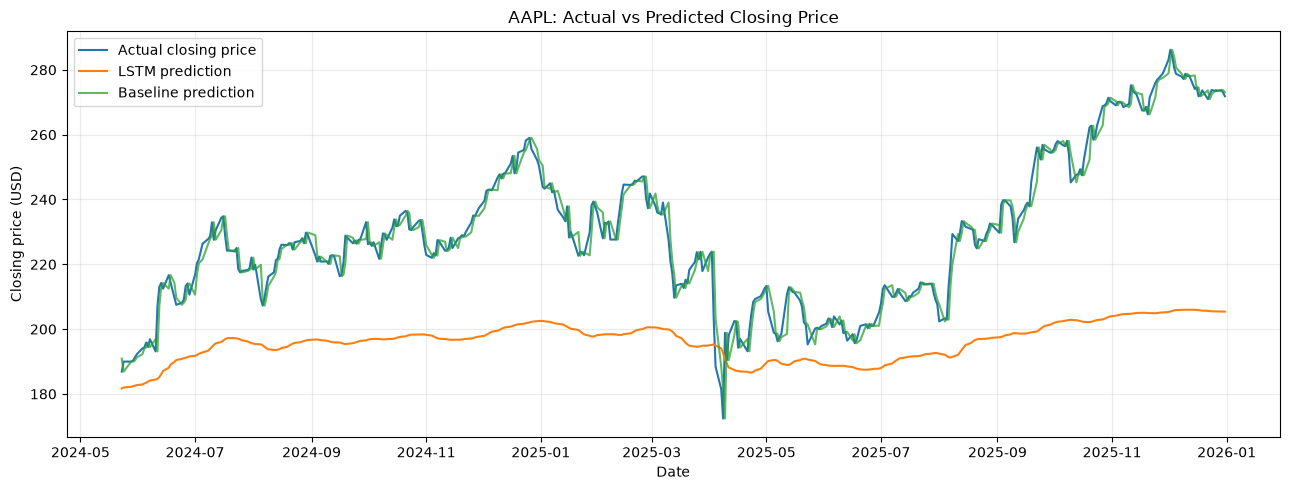

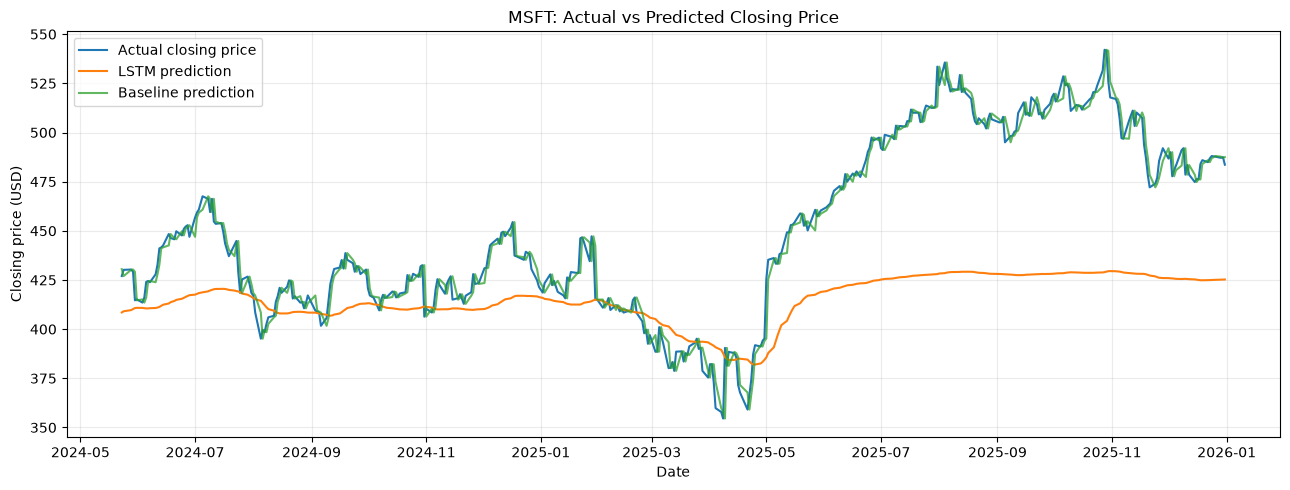

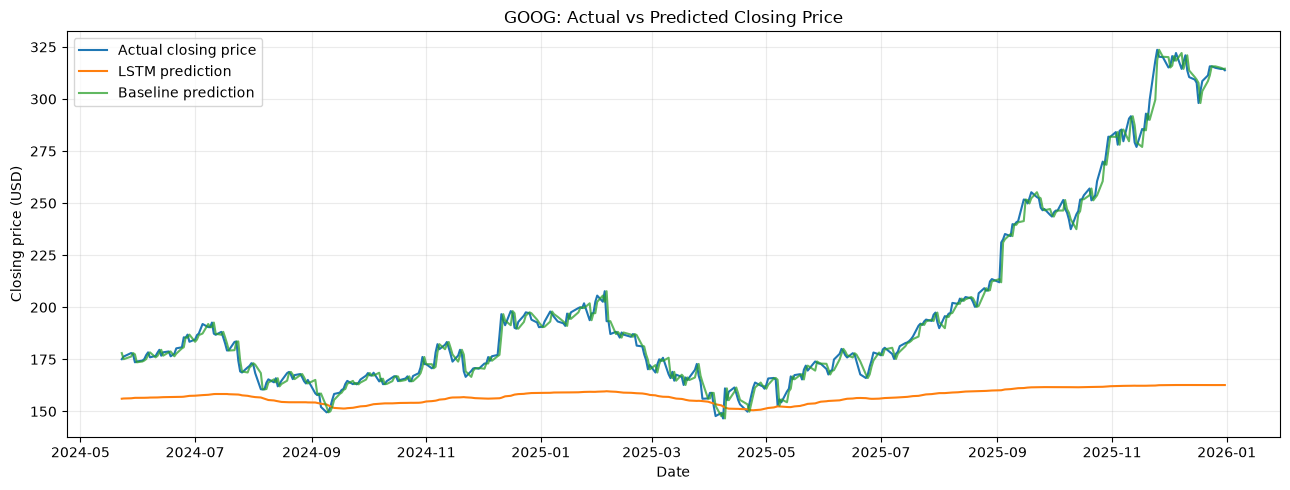

In [11]:
for ticker, result in results.items():
    plt.figure(figsize=(13, 5))
    plt.plot(result["dates"], result["actual"], label="Actual closing price")
    plt.plot(result["dates"], result["predicted"], label="LSTM prediction")
    plt.plot(result["dates"], result["baseline"], label="Baseline prediction", alpha=0.75)
    plt.title(f"{ticker}: Actual vs Predicted Closing Price")
    plt.xlabel("Date")
    plt.ylabel("Closing price (USD)")
    plt.legend()
    plt.grid(True, alpha=0.25)
    plt.tight_layout()
    plt.show()

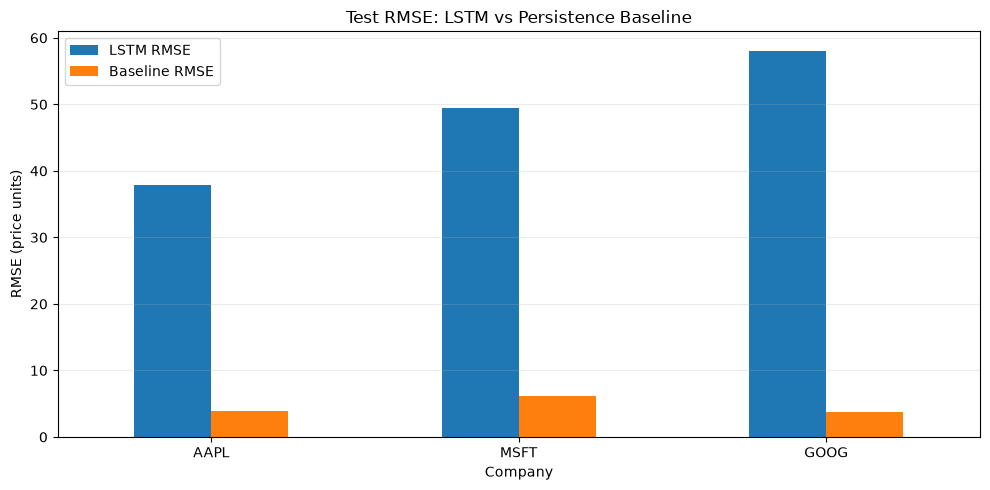

In [12]:
plot_data = comparison[["LSTM RMSE", "Baseline RMSE"]]
plot_data.plot(kind="bar", figsize=(10, 5))
plt.title("Test RMSE: LSTM vs Persistence Baseline")
plt.xlabel("Company")
plt.ylabel("RMSE (price units)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

In [13]:
best_ticker = comparison["LSTM RMSE"].idxmin()
print(f"Lowest LSTM test RMSE in this run: {best_ticker}")

for ticker, row in comparison.iterrows():
    if row["LSTM RMSE"] < row["Baseline RMSE"]:
        verdict = "LSTM had lower RMSE than the baseline"
    elif row["LSTM RMSE"] > row["Baseline RMSE"]:
        verdict = "Baseline had lower RMSE than the LSTM"
    else:
        verdict = "LSTM and baseline had equal RMSE"

    print(f"{ticker}: {verdict}. "
          f"LSTM RMSE={row['LSTM RMSE']:.3f}, "
          f"Baseline RMSE={row['Baseline RMSE']:.3f}")

Lowest LSTM test RMSE in this run: AAPL
AAPL: Baseline had lower RMSE than the LSTM. LSTM RMSE=37.816, Baseline RMSE=3.909
MSFT: Baseline had lower RMSE than the LSTM. LSTM RMSE=49.503, Baseline RMSE=6.164
GOOG: Baseline had lower RMSE than the LSTM. LSTM RMSE=58.077, Baseline RMSE=3.765
